In [29]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import DecisionTreeClassifier

In [220]:
# 1. Define hyperparameters
M = 30  # Number of trees in the ensemble
c = 2  # Number of leaf nodes per tree in the ensemble

In [221]:
# 2. Generate a non-linear synthetic dataset
data_problem="circles"
seed = 42
if data_problem=="circles":
    X, y = make_circles(n_samples=300, factor=0.5, noise=0.2, random_state=seed)
elif data_problem=="moon":
    X, y = make_moons(n_samples=300, noise=0.3, random_state=seed)
elif data_problem=="blobs":
    X, y = make_blobs(n_samples=300, centers=4, cluster_std=2, random_state=seed)

In [222]:
# 3. Define the three models
models = {
    f"Single Tree\n({M} × {c} = {M * c} max leaves)": DecisionTreeClassifier(
        max_leaf_nodes=M * c, random_state=seed
    ),
    f"Random Forest\n({M} trees, {c} leaves each)": RandomForestClassifier(
        n_estimators=M, max_leaf_nodes=c, random_state=seed
    ),
    f"Gradient Boosting\n({M} trees, {c} leaves each)": GradientBoostingClassifier(
        n_estimators=M, max_leaf_nodes=c, learning_rate=1, random_state=seed
    ),
}

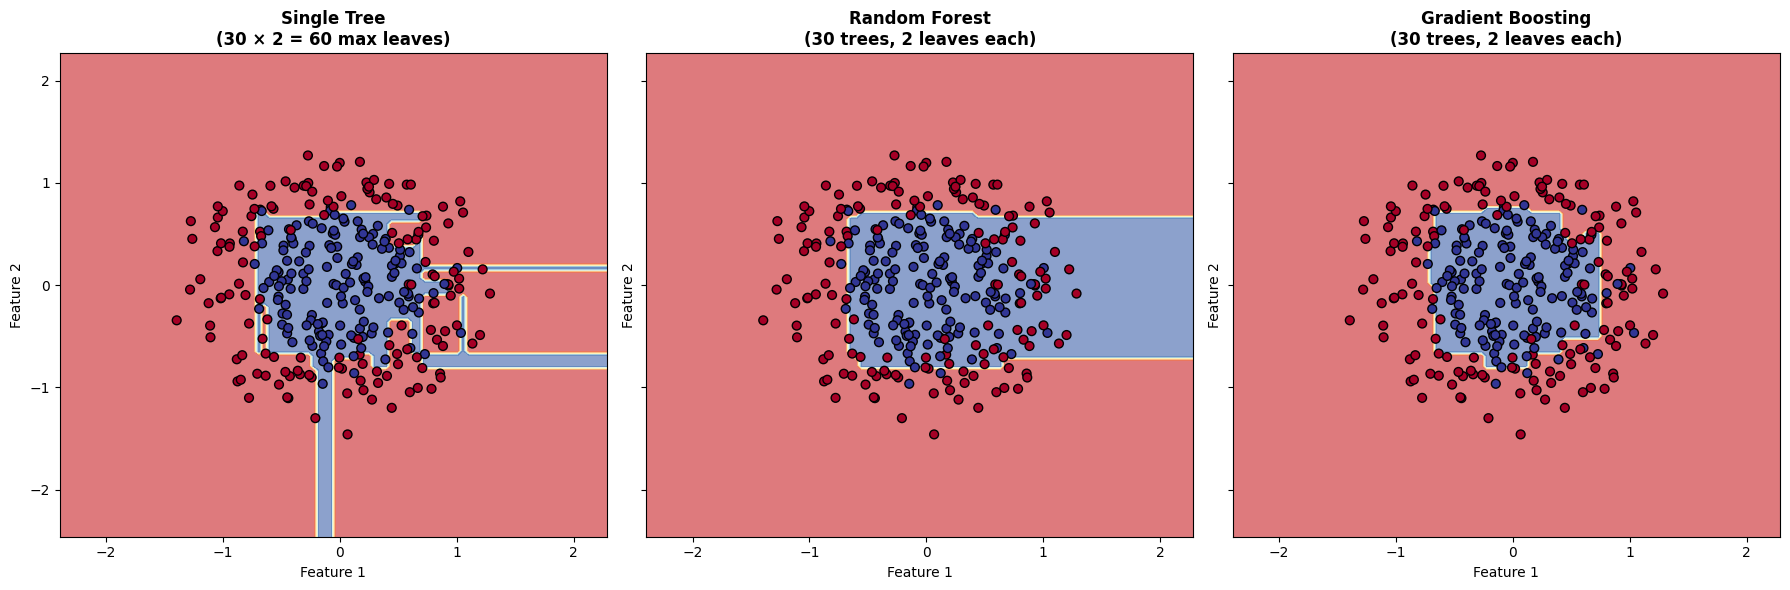

In [223]:

# 4. Train models and plot decision boundaries
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (title, model) in zip(axes, models.items()):
  # Fit the model
  model.fit(X, y)

  # Plot decision boundary
  disp = DecisionBoundaryDisplay.from_estimator(
      model,
      X,
      response_method="predict",
      cmap=plt.cm.RdYlBu,
      alpha=0.6,
      ax=ax,
      xlabel="Feature 1",
      ylabel="Feature 2",
  )


  # Plot the training points
  ax.scatter(
      X[:, 0],
      X[:, 1],
      c=y,
      cmap=plt.cm.RdYlBu,
      edgecolors="k",
      s=40,
      linewidth=1,
  )
  ax.set_title(title, fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()